In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from pptx import Presentation
from pptx.util import Inches
import openpyxl
import matplotlib as mpl
import streamlit as st

# 1. HIPÓTESIS
Con los datos recogidos vamos a realizar un estudio de mercado basado principalmente las ventas de videojuegos a nivel global y por regiones según el género de videojuegos.
* Análisis de ventas de videojuegos según la platarforma a nivel global y por regiones
* Análisis de ventas de videojuegos según el fabricante de la consola a nivel global y por regiones
* Análisis de ventas de videojuegos según su género a nivel global y por regiones
* Análisis de ventas de videojuegos según su género a lo largo de los años, a nivel global y por regiones


# 2. ANÁLISIS DE DATOS

In [2]:
archivo = '../data/videojuegos.csv'
df = pd.read_csv(archivo)
df.head()

,Game,Platform,Manufacturer,Year,Genre,Publisher,North America,Europe,Japan,Rest of World,Global
0,Grand Theft Auto V,PS4,Sony,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,PS4,Sony,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,PS4,Sony,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,Call of Duty: WWII,PS4,Sony,2017.0,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,FIFA 18,PS4,Sony,2017.0,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80


In [9]:
df['Year'] = df['Year'].astype('Int64')

## Análisis descriptivo

In [20]:
df[['North America','Europe','Japan','Rest of World','Global']].describe()

,North America,Europe,Japan,Rest of World,Global
count,23178.000000,23178.000000,23178.000000,23178.000000,23178.000000
mean,0.292838,0.179921,0.072677,0.059235,0.604891
std,0.868053,0.596062,0.307926,0.203402,1.723504
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.010000,0.000000,0.000000,0.000000,0.060000
50%,0.090000,0.030000,0.000000,0.010000,0.190000
75%,0.270000,0.140000,0.030000,0.050000,0.540000
max,41.490000,29.020000,10.220000,10.570000,82.740000


## Ventas de Videojuegos Según la Plataforma a nivel Mundial y por Regiones

In [24]:
df_platform = df.groupby('Platform')['Global'].sum().sort_values(ascending=False)
df.groupby('Platform').agg({'Game':'count','Global':['sum','mean']})

Game   Global          
         count      sum      mean
Platform                         
2600       133    97.08  0.729925
3DO          3     0.10  0.033333
3DS        692   445.84  0.644277
DC          52    15.97  0.307115
DS        3031  1469.45  0.484807
GB          98   255.45  2.606633
GBA        822   318.50  0.387470
GC         556   199.36  0.358561
GEN         27    28.36  1.050370
GG           1     0.04  0.040000
N64        319   218.88  0.686144
NES         98   251.07  2.561939
NG          12     1.44  0.120000
PC        1328   395.17  0.297568
PCFX         1     0.03  0.030000
PS        1197   730.68  0.610426
PS2       2162  1256.92  0.581369
PS3       2223  1816.53  0.817152
PS4       1658  1178.39  0.710730
PSP       1488   464.40  0.312097
PSV        625   104.66  0.167456
SAT        173    33.59  0.194162
SCD          6     1.87  0.311667
SNES       239   200.05  0.837029
TG16         2     0.16  0.080000
WS           6     1.42  0.236667
Wii       2180  1770.14  0.811991
WiiU       257   160.32  0.623813
X360      1938  1782.26  0.919639
XB         824   258.26  0.313422
Xbox One  1027   563.77  0.548948

Analizar:

Ventas totales
Número de juegos por plataforma
Media de ventas por juego

In [ ]:
ventas_plataforma = (df.groupby('Platform')['Global'].sum().sort_values(ascending=False).reset_index())

ventas_plataforma.head()

,Platform,Global
0,PS3,1816.53
1,X360,1782.26
2,Wii,1770.14
3,DS,1469.45
4,PS2,1256.92


C:\Users\bgran\AppData\Local\Temp\ipykernel_15548\1462548732.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


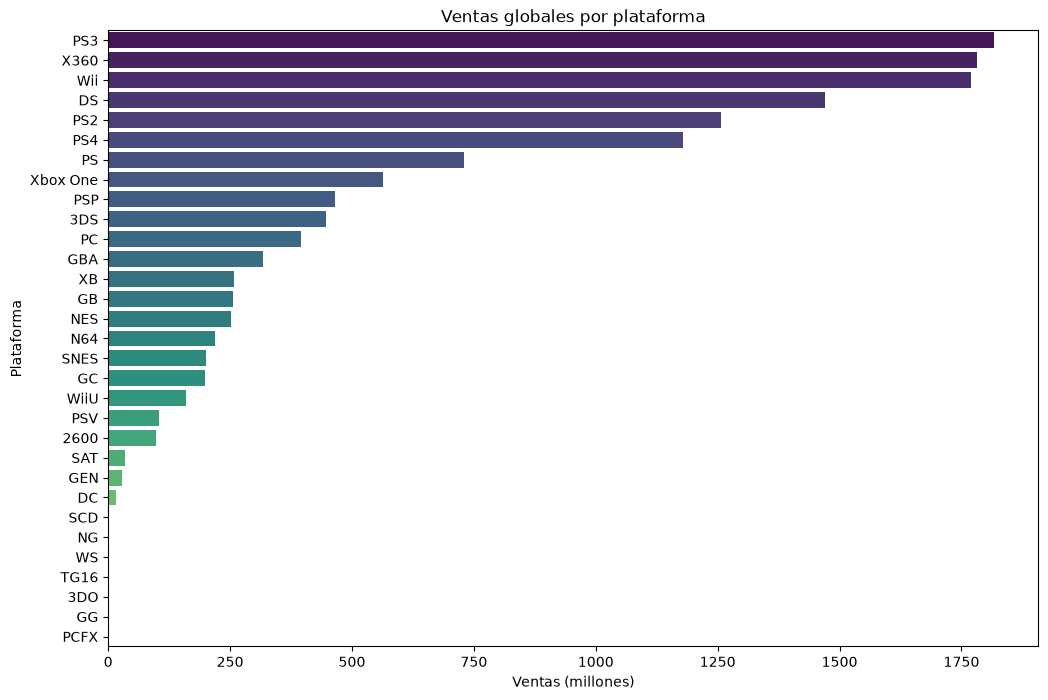

In [ ]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=ventas_plataforma,
    x='Global',
    y='Platform',
    palette='viridis'
)

plt.title('Ventas globales por plataforma')
plt.xlabel('Ventas (millones)')
plt.ylabel('Plataforma')

plt.show()

En la gráfica se puede ver como las plataformas PS3, X360 y Wii son las que mayor número de ventas de videojuegos generan. Cada una de ellas pertenece a un fabricante diferente: Sony, Microsoft y Nintendo, respectivamente.

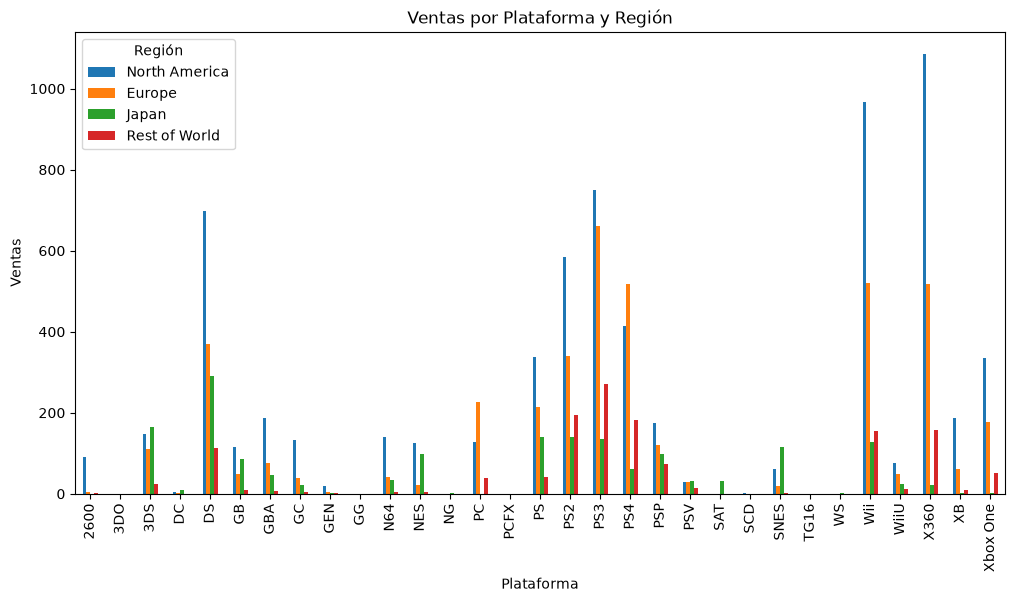

In [4]:
df_plot = df.groupby('Platform')[['North America','Europe','Japan','Rest of World']].sum()

df_plot.plot(kind='bar',figsize=(12,6))

plt.title('Ventas por Plataforma y Región')
plt.xlabel('Plataforma')
plt.ylabel('Ventas')
plt.legend(title='Región')
plt.show()

Cuando se separa las ventas de videojuegos según las plataformas y las regiones, se puede ver que en muchas destaca como mayoritaria las ventas en Norte América como la X360 de Microsoft y la Wii y la DS de Nintendo. Sin embargo, si miramos las plataformas de Sony (Playstation) las ventas por regiones aparecen bastantes más igualadas.

## Ventas de Videojuegos según el Fabricante a nivel Global y por Regiones

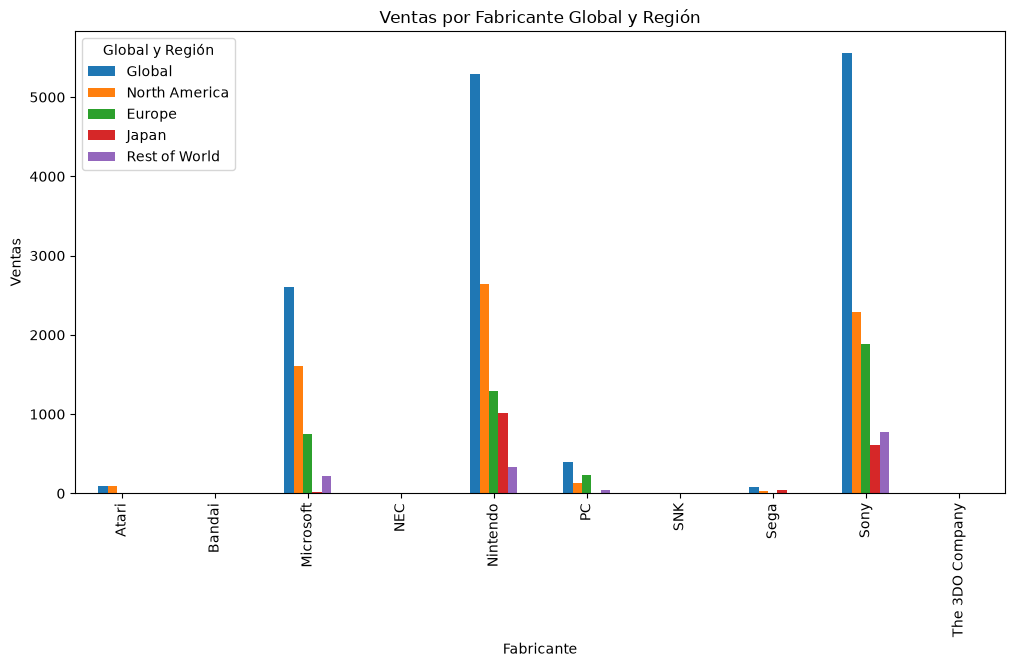

In [7]:
df_plot = df.groupby('Manufacturer')[['Global','North America','Europe','Japan','Rest of World']].sum()

df_plot.plot(kind='bar',figsize=(12,6))

plt.title('Ventas por Fabricante Global y Región')
plt.xlabel('Fabricante')
plt.ylabel('Ventas')
plt.legend(title='Global y Región')
plt.show()

Si analizamos las ventas por fabricante de las plataformas podemos ver que tanto Sony como Nintendo están muy igualados, tanto a nivel mundial como por regiones.

## Ventas de Videojuegos por Género a Nivel Mundial y Por Regiones

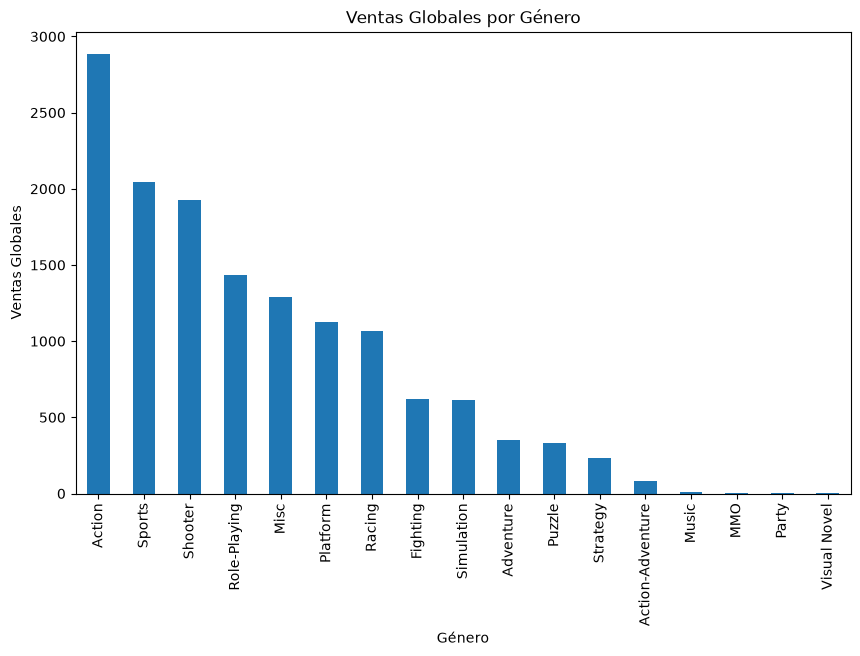

In [5]:
df_platform = df.groupby('Genre')['Global'].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
df_platform.plot(kind='bar')
plt.title('Ventas Globales por Género')
plt.xlabel('Género')
plt.ylabel('Ventas Globales')
plt.show()

Se puede ver claramente en la gráfica que los videojuegos de acción son los más vendidos, seguidos por los de deportes y disparos que están más o menos igualados.

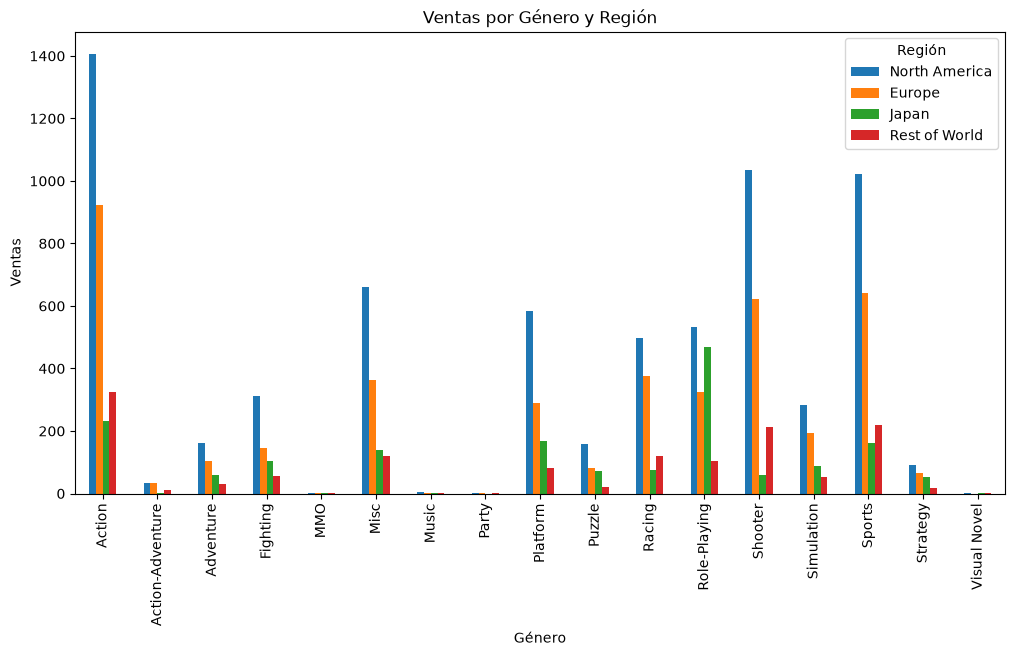

In [6]:
df_plot = df.groupby('Genre')[['North America','Europe','Japan','Rest of World']].sum()

df_plot.plot(kind='bar',figsize=(12,6))

plt.title('Ventas por Género y Región')
plt.xlabel('Género')
plt.ylabel('Ventas')
plt.legend(title='Región')
plt.show()

Al analizar las ventas por regiones, se puede ver que Norte América vende más videojuegos en general de cualquier género, y después Europa. Aunque Japón, produce una anomalía en los videojuegos de rol, ya que clase iguala en ventas a Norte América y supera a Europa.

## Ventas de Videojuegos por Género a lo Largo de Los Años a nivel Global y por Regiones

In [17]:
ranking = (df.groupby("Genre")["Global"].sum().sort_values(ascending=False))

genres = ranking.index.tolist()

mitad = len(genres) // 2

grupo1 = genres[:mitad]      # géneros con más ventas
grupo2 = genres[mitad:]      # géneros con menos ventas

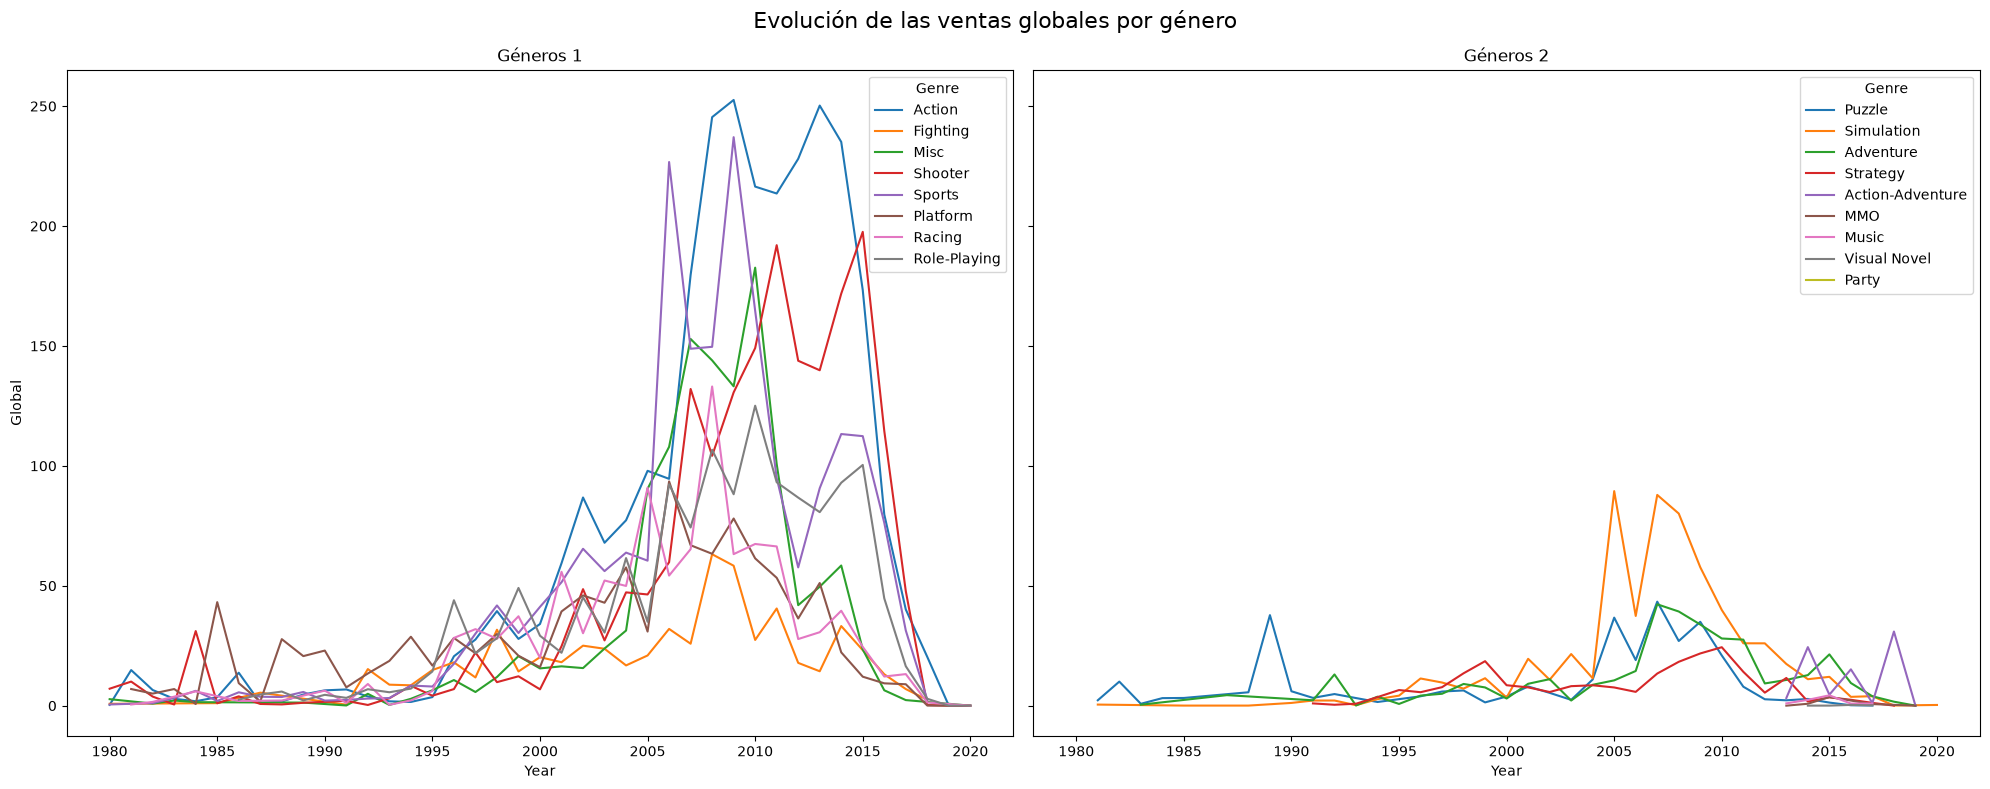

In [18]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 8),
    sharex=True,
    sharey=True
)

sns.lineplot(
    data=ventas_genero_global[
        ventas_genero_global["Genre"].isin(grupo1)
    ],
    x="Year",
    y="Global",
    hue="Genre",
    ax=axes[0]
)

sns.lineplot(
    data=ventas_genero_global[
        ventas_genero_global["Genre"].isin(grupo2)
    ],
    x="Year",
    y="Global",
    hue="Genre",
    ax=axes[1]
)

axes[0].set_title("Géneros 1")
axes[1].set_title("Géneros 2")

plt.suptitle(
    "Evolución de las ventas globales por género",
    fontsize=16
)

plt.tight_layout()
plt.show()

Qué podrás analizar
Cuándo alcanzó su máximo cada género.
Qué géneros dominaron cada década.
Qué géneros han perdido popularidad.
Aparición de nuevos géneros.

In [ ]:
ventas_region = df.melt(id_vars=["Year", "Genre"],value_vars=["North America", "Europe", "Japan", "Rest of World"],var_name="Region",value_name="Sales")
ranking = (df.groupby("Genre")["Global"].sum().sort_values(ascending=False))

genres = ranking.index.tolist()

mitad = len(genres) // 2

grupo1 = genres[:mitad]
grupo2 = genres[mitad:]

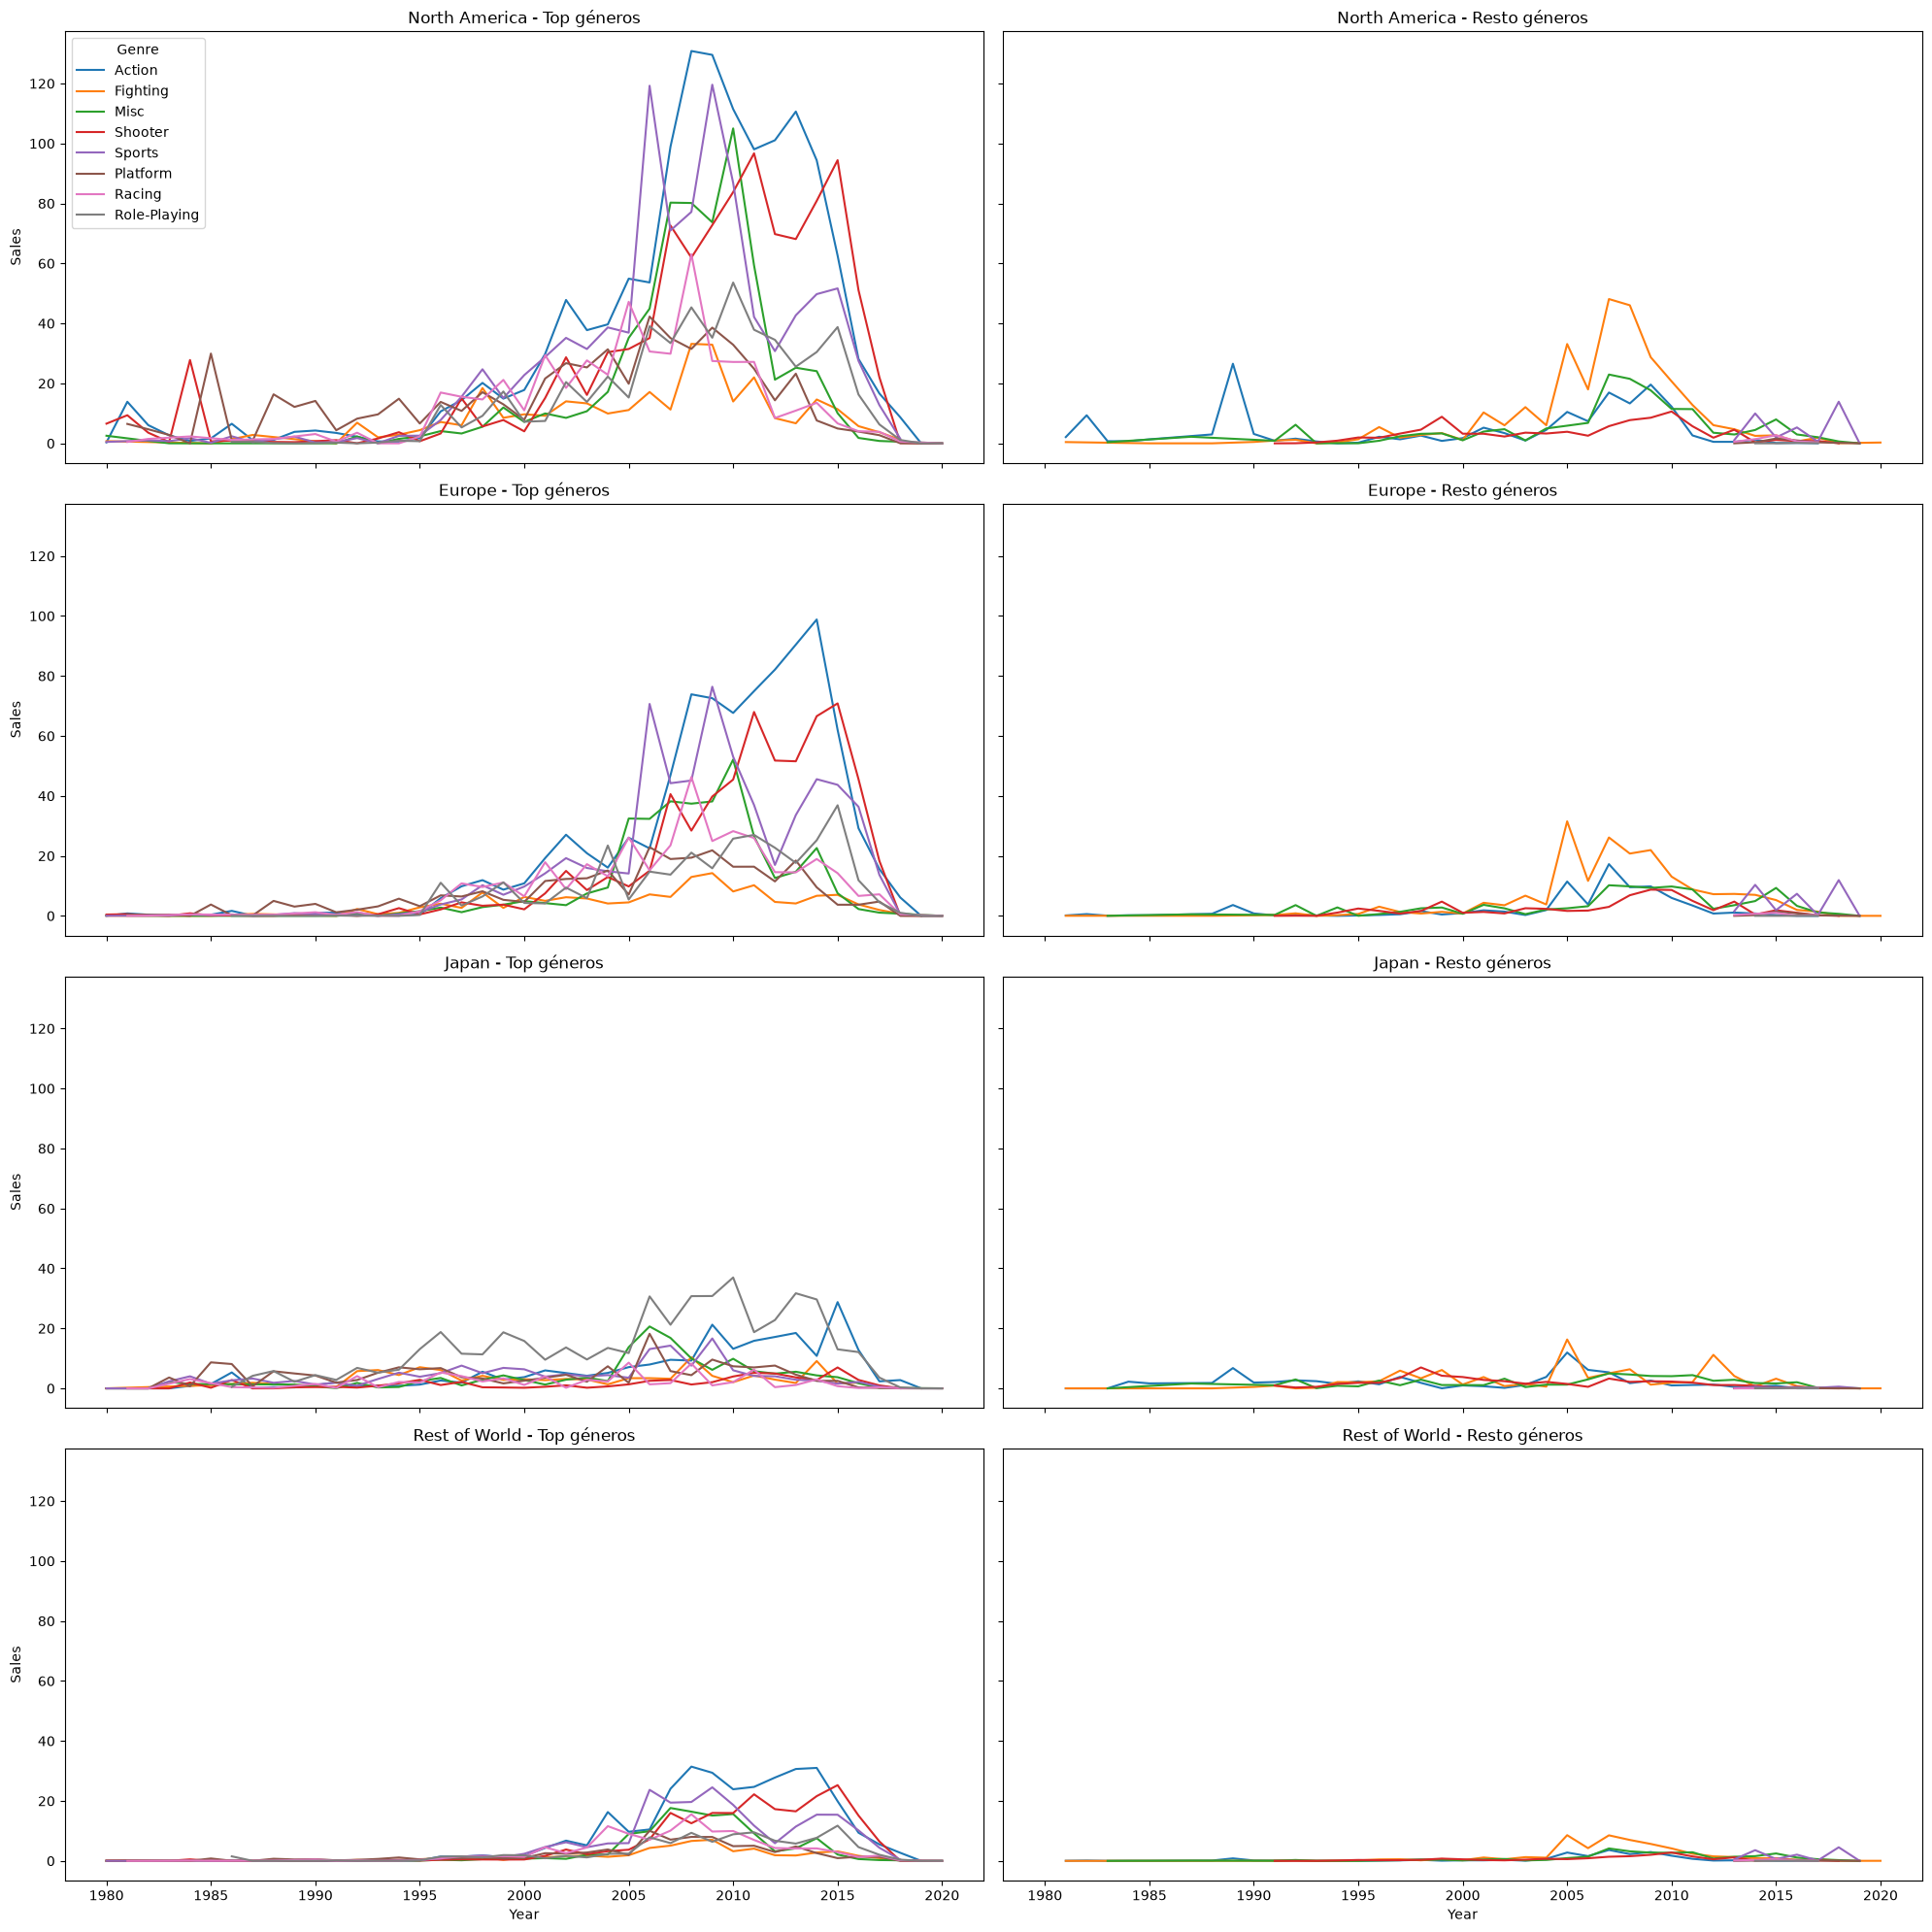

In [19]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(20, 20),
    sharex=True,
    sharey=True
)

regiones = [
    "North America",
    "Europe",
    "Japan",
    "Rest of World"
]

for i, region in enumerate(regiones):

    datos_region = (
        ventas_region[ventas_region["Region"] == region]
        .groupby(["Year", "Genre"])["Sales"]
        .sum()
        .reset_index()
    )

    sns.lineplot(
        data=datos_region[
            datos_region["Genre"].isin(grupo1)
        ],
        x="Year",
        y="Sales",
        hue="Genre",
        ax=axes[i, 0],
        legend=(i == 0)
    )

    sns.lineplot(
        data=datos_region[
            datos_region["Genre"].isin(grupo2)
        ],
        x="Year",
        y="Sales",
        hue="Genre",
        ax=axes[i, 1],
        legend=False
    )

    axes[i, 0].set_title(f"{region} - Top géneros")
    axes[i, 1].set_title(f"{region} - Resto géneros")

plt.tight_layout()
plt.show()